# Gold ETF trading activity

Rank the five configured gold ETFs by mean daily **trade count** (number of transactions) during the last 90 calendar days ending at the latest date shared by their price histories. Only sessions with positive trade count and volume enter the calculation. Source: canonical TSETMC daily price CSVs, updated by `collect_daily.py`. The notebook reads those files and never changes raw data.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

def project_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        candidate = base / 'commodity' / 'gold'
        if (candidate / 'config' / 'funds.json').exists():
            return candidate
        if (base / 'config' / 'funds.json').exists() and (base / 'collect_daily.py').exists():
            return base
    raise FileNotFoundError('Run from the workspace or gold project tree')

project = project_dir()
funds = {'ayar': 'Ayar', 'tala': 'Tala', 'kahroba': 'Kahroba', 'ganj': 'Ganj', 'gohar': 'Gohar'}
prices = {}
for key in funds:
    frame = pd.read_csv(project / 'data' / 'raw' / 'funds' / key / 'price.csv', parse_dates=['date'])
    if frame.date.duplicated().any():
        raise ValueError(f'{key}: duplicate price dates')
    prices[key] = frame
end = min(frame.date.max() for frame in prices.values())
start = end - pd.Timedelta(days=89)
print(f'Comparison window: {start.date()} to {end.date()} (90 calendar days)')


Comparison window: 2026-07-17 to 2026-10-14 (90 calendar days)


In [2]:
activity = []
for key, frame in prices.items():
    traded = frame.loc[frame.date.between(start, end) & (frame.trade_count > 0) & (frame.trade_volume > 0)].copy()
    traded['fund'] = funds[key]
    activity.append(traded)
activity = pd.concat(activity, ignore_index=True)
summary = (activity.groupby('fund', as_index=False)
           .agg(trading_days=('date', 'size'), average_transactions=('trade_count', 'mean'),
                median_transactions=('trade_count', 'median'), average_units=('trade_volume', 'mean'))
           .sort_values('average_transactions', ascending=False).reset_index(drop=True))
summary.insert(0, 'rank', range(1, len(summary) + 1))
display(summary.round({'average_transactions': 0, 'median_transactions': 0, 'average_units': 0}))


,rank,fund,trading_days,average_transactions,median_transactions,average_units
0,1,Ayar,62,110332.0,105830.0,112544888.0
1,2,Tala,62,23442.0,22269.0,9904898.0
2,3,Kahroba,62,18169.0,16798.0,41331378.0
3,4,Ganj,62,13715.0,13680.0,30104481.0
4,5,Gohar,61,8651.0,8102.0,60002297.0


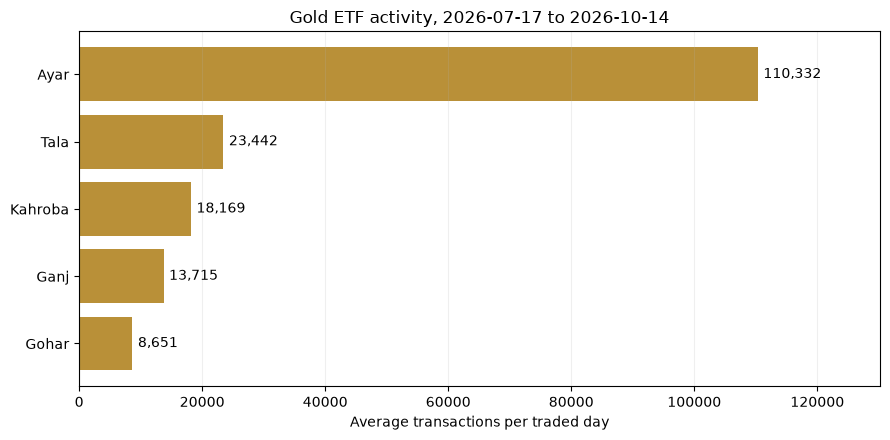

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
top = summary.head(5).iloc[::-1]
bars = ax.barh(top.fund, top.average_transactions, color='#b99038')
ax.bar_label(bars, labels=[f'{value:,.0f}' for value in top.average_transactions], padding=4)
ax.set(xlabel='Average transactions per traded day', title=f'Gold ETF activity, {start.date()} to {end.date()}')
ax.set_xlim(0, summary.average_transactions.max() * 1.18)
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
plt.show()


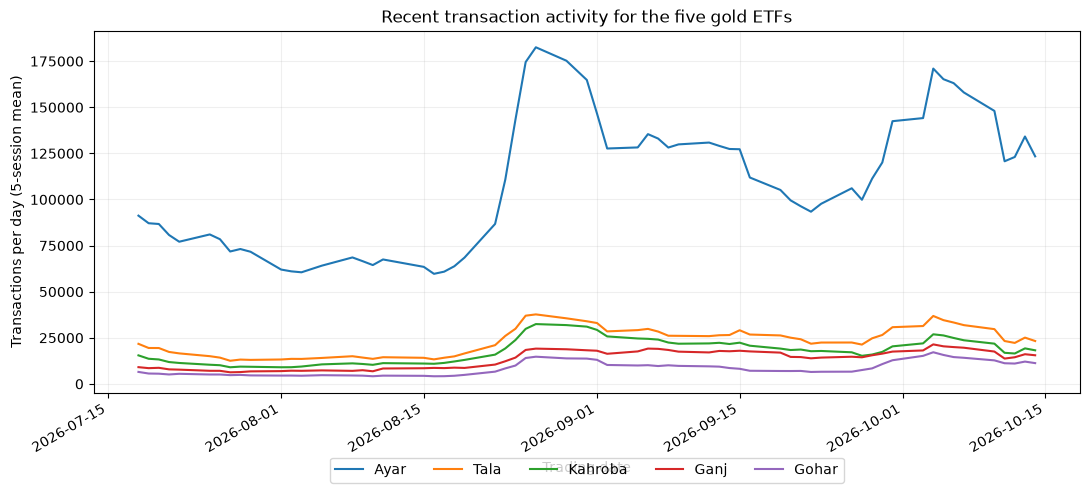

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
for fund in summary.head(5).fund:
    series = activity.loc[activity.fund.eq(fund)].sort_values('date').set_index('date').trade_count
    ax.plot(series.index, series.rolling(5, min_periods=1).mean(), label=fund)
ax.set(xlabel='Trading date', ylabel='Transactions per day (5-session mean)',
       title='Recent transaction activity for the five gold ETFs')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(.5, -0.16))
ax.grid(alpha=.2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


Trade count measures transaction frequency, not traded value. The ranking covers the five configured funds and the available common 90-day window; it is not a survey of every listed Iranian gold ETF. Rerun the documented collector before rerunning this notebook for a newer checkpoint.
